# Fashion Mnist: Loading and understanding image data

## 1. Loading and Inspecting the dataset

In [1]:
import torch
import torchvision
import torch.nn as nn
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130


torchvision provides datasets and image-processing tools that work with PyTorch. Fashion-MNIST is available directly through its datasets API.

In [2]:
transform = transforms.ToTensor()

full_train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training dataset:", len(full_train_dataset))
print("Test dataset:", len(test_dataset))

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.5MB/s]

Training dataset: 60000
Test dataset: 10000


What does transforms.ToTensor() do?

Fashion-MNIST images start as grayscale images with pixel intensities from 0 to 255. ToTensor() converts each image into a PyTorch tensor, changes the layout to channels × height × width, and scales these pixel values to the range 0 to 1 for standard 8-bit images.

So one image have shape: (1, 28, 28): grayscale channel, height, width

Notice that even a grayscale image has a channel dimension. RGB images generally have three channels instead.

## 2. Separate Training and validation Data

In [3]:
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [55000, 5000],
    generator=generator
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("="*60)
print("We will use the validation set during development and keep the official test set for final evaluation.")

Training: 55000
Validation: 5000
Test: 10000
We will use the validation set during development and keep the official test set for final evaluation.


## 3. Inspect one image

Image shape: torch.Size([1, 28, 28])
Label: 9
Class: Ankle boot
Minimum pixel: 0.0
Maximum pixel: 1.0


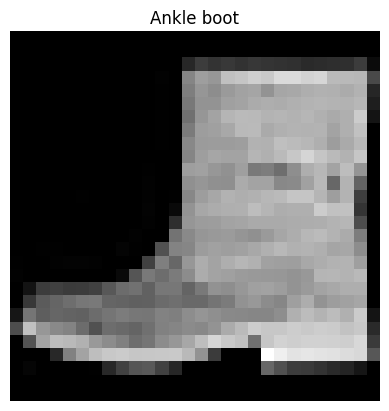

In [4]:
import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class:", class_names[label])
print("Minimum pixel:", image.min().item())
print("Maximum pixel:", image.max().item())

plt.imshow(image.squeeze(0), cmap="gray") # squeeze makes it (28 * 28 ) instead of (1*28*28)
plt.title(class_names[label])
plt.axis("off")
plt.show()

## 4. Create the Dataloaders


In [5]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])


### The fact is we have to flatten our image to build an MLP
A standard fully connected neural network (MLP) expects each example to be represented as a one-dimensional feature vector. So we transform:

original image: (1, 28, 28)
flattened: (784,) one vector containing all pixels

Flattening changes the shape, not the pixel values. It doesn't make the image larger or add information; it rearranges the values into a vector.

In [6]:
image, label = train_dataset[0]

print("Before flattening:", image.shape)

flattened_image = image.flatten()

print("After flattening:", flattened_image.shape)
print("Number of pixel values:", flattened_image.numel())

Before flattening: torch.Size([1, 28, 28])
After flattening: torch.Size([784])
Number of pixel values: 784


In [7]:
# Let's flatten a whole batch
image, labels = next(iter(train_loader))
print("Before:", images.shape)

flattened_images = images.flatten(start_dim=1)
print("After:", flattened_images.shape)
print("Labels:", labels.shape)

Before: torch.Size([64, 1, 28, 28])
After: torch.Size([64, 784])
Labels: torch.Size([64])


Why start_dim=1?

The first dimension, index 0, represents the batch of 64 separate images. We must preserve that dimension.
- images.flatten(start_dim=1) keeps the 64 images separate and flattens each image.
- images.flatten() with no argument would flatten the entire batch into one long vector of 50,176 values, losing the batch structure.

## Building our first Fashion-MNIST MLP
- Input Layer: 784 features (All pixels from one image)
- Hidden Layer: 128 Neurons (Learn useful combinations of pixel values)
- Output Layer: 10 scores(logits)-- one score for each clothing class

In [8]:
import torch
import torch.nn as nn

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


In [9]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


Why (64, 10)?
- 64 means the model processed 64 images.
- 10 means it produced 10 scores for each image, one per class.

These scores are called logits. They are not necessarily probabilities, and they don't have to sum to 1.

In [11]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

epochs = 5

for epoch in range(epochs):
  model.train()
  total_loss = 0.0
  total_correct = 0
  total_samples = 0

  for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    # Forward pass
    outputs = model(images)

    # loss
    loss = criterion(outputs, labels)

    # Clear old gradients
    optimizer.zero_grad()

    # backpropagation
    loss.backward()

    # update params
    optimizer.step()

    # Track training statistics
    batch_size = labels.size(0)
    total_loss += loss.item() * batch_size # loss.item() gives avg. loss for current batch

    # outputs have shape : (64, 10)
    # dim=1 means in that row calculated scores for each labels means 10 scores give me the highes score index so i can predict that you are that one
    predictions = outputs.argmax(dim=1)
    total_correct += (predictions == labels).sum().item()
    total_samples += batch_size # count all processed images

  train_loss = total_loss/total_samples
  train_accuracy = total_correct/total_samples

  print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%}"
  )


Epoch 1/5 | Train Loss: 1.1968 | Train Accuracy: 64.13%
Epoch 2/5 | Train Loss: 0.6888 | Train Accuracy: 76.72%
Epoch 3/5 | Train Loss: 0.5866 | Train Accuracy: 80.36%
Epoch 4/5 | Train Loss: 0.5366 | Train Accuracy: 81.90%
Epoch 5/5 | Train Loss: 0.5070 | Train Accuracy: 82.75%


## Evaluate of validation data

In [15]:
model.eval()

val_loss_total = 0.0
val_correct = 0
val_samples = 0

with torch.no_grad():
  for images, labels in val_loader:
    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)
    loss = criterion(outputs, labels)

    batch_size = labels.size(0)
    val_loss_total += loss.item() * batch_size

    predictions = outputs.argmax(dim=1)
    val_correct += (predictions == labels).sum().item()
    val_samples += batch_size

val_loss = val_loss_total / val_samples
val_accuracy = val_correct / val_samples

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2%}")

Validation Loss: 0.5385
Validation Accuracy: 81.22%


In [16]:
model.eval()

test_loss_total = 0.0
test_correct = 0
test_samples = 0

with torch.no_grad():
  for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)
    loss = criterion(outputs, labels)

    batch_size = labels.size(0)

    test_loss_total += loss.item() * batch_size

    predictions = outputs.argmax(dim=1)
    test_correct += (predictions == labels).sum().item()
    test_samples += batch_size

test_loss = test_loss_total / test_samples
test_accuracy = test_correct / test_samples

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Correct predictions: {test_correct}/{test_samples}")

Test Loss: 0.5387
Test Accuracy: 81.02%
Correct predictions: 8102/10000
